<a href="https://colab.research.google.com/github/slee7286/recruit-holdings-workshop/blob/main/Hotel_Revenue_Management_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hotel revenue management workshop — Google Colab

**No local Python, GitHub account or Drive mount is required.** All inputs are invented and included in this notebook. Use a standard CPU runtime.

1. Choose **File → Save a copy in Drive** to make your own copy.
2. Connect to a runtime, then choose **Runtime → Run all**.
3. Inspect the distributions, optimal price tables and optimal expected revenue tables.
4. Change only `wtp_mean` below from **18000** to **21000** (or **15000**) and run all again. Each run creates a new experiment folder; earlier results remain available while this runtime exists.
5. Download your results at the end before closing the runtime. Saving this notebook to Drive does not save files created in the runtime.

If Colab requests a restart after package installation, restart the session and run all again.

**日本語:** 「ファイル → ドライブにコピーを保存」で自分用のコピーを作り、接続後に「ランタイム → すべてのセルを実行」を選びます。結果を確認したら下の `wtp_mean` を 18000 から 21000 に変更して再実行してください。最後に結果をダウンロードします。Drive のマウントや GitHub の認証は不要です。

This notebook adapts the synthetic setup and Notebooks 02–03 from the workshop. Only teaching source code is embedded; no client data or repository history is included.


In [ ]:
%pip install -q "numpy>=1.26,<3" "pandas>=2.2,<4" "scipy>=1.13,<2" "matplotlib>=3.9,<4" "seaborn>=0.13,<0.14" "PyYAML>=6.0.3,<7"


## 1. Choose your experiment

Start with the defaults. Change one assumption at a time. WTP is normally distributed; all prices use arbitrary currency units. The upper price bound is excluded. Demand multipliers must be positive, unique and include 1.0. The daily arrival probability must not exceed one.

**日本語:** 初回は初期値のまま実行します。2 回目は支払意思額の平均 `wtp_mean` だけを変更してください。設定を変えたら、このセル以降をすべて実行します。


In [ ]:
# Edit these values, then run all cells again.
wtp_mean = 18000  # Try 21000 or 15000 for the next experiment.
wtp_std = 6000
capacity = 10
leadtime = 60  # Includes check-in day 0.
people = 18  # Expected potential arrivals over the whole horizon at demand x 1.
demand_multipliers = [0.6, 1.0, 1.2]
price_min, price_max, price_step = 5000, 35000, 1000
arrival_log_mean, arrival_log_std = 3.0, 0.8


## 2. Generate synthetic inputs

This cell creates fresh inputs for this experiment. You do not need to upload any CSV or model files. The helper functions validate the settings before generating the distributions.


In [ ]:
import os
import json
import pickle
import tempfile
import platform
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
from scipy.stats import lognorm
import yaml
from IPython.display import display

def _number(value, name, lower=0, upper=np.inf, integer=False, positive=False):
    if (isinstance(value, bool) or not isinstance(value, (int, float))
            or not np.isfinite(value) or value < lower or value > upper
            or (positive and value <= 0) or (integer and not isinstance(value, int))):
        raise ValueError(f'Invalid {name}: {value!r}')
    return value

def build_parameters(scenario):
    """Return the runtime configuration and three deterministic pricing inputs."""
    s = scenario
    required = {'name', 'leadtime', 'capacity', 'people', 'price_interval',
                'mt_multiplier', 'wtp', 'price', 'arrival'}
    if set(s) != required:
        raise ValueError(f'Scenario fields must be exactly: {sorted(required)}')
    for key in ('leadtime', 'capacity', 'price_interval'):
        _number(s[key], key, integer=True, positive=True)
    _number(s['people'], 'people', positive=True)
    multipliers = s['mt_multiplier']
    if not isinstance(multipliers, list) or not multipliers:
        raise ValueError('mt_multiplier must be a non-empty list')
    for value in multipliers:
        _number(value, 'mt_multiplier', positive=True)
    if 1.0 not in multipliers or len(set(multipliers)) != len(multipliers):
        raise ValueError('mt_multiplier must be unique and include baseline 1.0')
    mu = _number(s['wtp']['mean'], 'wtp.mean', positive=True)
    sigma = _number(s['wtp']['std'], 'wtp.std', positive=True)
    low = _number(s['price']['min'], 'price.min', positive=True, integer=True)
    high = _number(s['price']['max'], 'price.max', positive=True, integer=True)
    if high <= low:
        raise ValueError('price.max must exceed price.min')
    log_mean = _number(s['arrival']['log_mean'], 'arrival.log_mean', lower=-100, upper=100)
    log_std = _number(s['arrival']['log_std'], 'arrival.log_std', positive=True)
    weights = np.diff(lognorm.cdf(np.arange(s['leadtime'] + 2),
                                  s=log_std, scale=np.exp(log_mean)))
    if not np.isfinite(weights.sum()) or weights.sum() <= 0:
        raise ValueError('Arrival distribution has no representable mass in the horizon')
    weights /= weights.sum()
    if weights.max() * s['people'] * max(multipliers) > 1:
        raise ValueError('Arrival probability exceeds 1; reduce people/multipliers or broaden the arrival curve')
    config = {key: s[key] for key in ('leadtime', 'capacity', 'people', 'price_interval', 'mt_multiplier')}
    config.update(input_source='synthetic', scenario=s['name'], workflow='pricing-workshop-v1')
    models = {
        'opt_table_params': [low, high, s['price_interval']],
        'wtp_parameters': [mu, sigma],
        'visit_curve': pd.DataFrame({'visit': weights}),
    }
    return config, models

scenario = {
    'name': f'wtp_{wtp_mean}', 'leadtime': leadtime, 'capacity': capacity,
    'people': people, 'price_interval': price_step,
    'mt_multiplier': demand_multipliers,
    'wtp': {'mean': wtp_mean, 'std': wtp_std},
    'price': {'min': price_min, 'max': price_max},
    'arrival': {'log_mean': arrival_log_mean, 'log_std': arrival_log_std},
}
config, models = build_parameters(scenario)
# A new directory on every run preserves earlier experiments in this runtime.
results_root = Path(tempfile.gettempdir()) / 'hotel-pricing-colab'
results_root.mkdir(exist_ok=True)
experiment_dir = Path(tempfile.mkdtemp(prefix=f'wtp-{wtp_mean}-', dir=results_root))
for folder in ('model', 'result', 'fig'):
    (experiment_dir / folder).mkdir()
for name, model in models.items():
    with (experiment_dir / 'model' / f'{name}.pickle').open('wb') as file:
        pickle.dump(model, file)
(experiment_dir / 'config.yaml').write_text(yaml.safe_dump(config))
(experiment_dir / 'scenario.yaml').write_text(yaml.safe_dump(scenario))
(experiment_dir / 'environment.json').write_text(json.dumps({
    'python': platform.python_version(),
    'packages': {name: version(name) for name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'seaborn', 'PyYAML']},
}, indent=2))
os.chdir(experiment_dir)
print(f'Experiment: {experiment_dir.name}')
display(pd.Series(scenario, name='Scenario'))


Experiment: wtp-18000-yhv4z8p2


,Scenario
name,wtp_18000
leadtime,60
capacity,10
people,18
price_interval,1000
mt_multiplier,"[0.6, 1.0, 1.2]"
wtp,"{'mean': 18000, 'std': 6000}"
price,"{'min': 5000, 'max': 35000}"
arrival,"{'log_mean': 3.0, 'log_std': 0.8}"


## 3. Explore the distributions

In [ ]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display
import yaml

with open('config.yaml', encoding='utf-8') as file:
    config = yaml.safe_load(file)
assert config.get('workflow') == 'pricing-workshop-v1', 'Generate a fresh workspace with Notebook 01 first.'

def load_model(name):
    with open(f'model/{name}.pickle', 'rb') as file:
        return pickle.load(file)

mu, sigma = load_model('wtp_parameters')
price_min, price_max, price_step = load_model('opt_table_params')
visit = load_model('visit_curve')
days = np.arange(config['leadtime'] + 1)
figure_dir = Path('fig/distributions')
figure_dir.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')

def save_chart(fig, name):
    fig.tight_layout()
    fig.savefig(figure_dir / name, dpi=140, bbox_inches='tight')
    plt.show()
    plt.close(fig)

display(pd.DataFrame([
    ('Scenario', config['scenario']),
    ('Room capacity', config['capacity']),
    ('Maximum days before check-in', config['leadtime']),
    ('Expected potential arrivals at multiplier 1', config['people']),
    ('WTP mean / standard deviation', f'{mu:g} / {sigma:g}'),
], columns=['Parameter', 'Value']))

,Parameter,Value
0,Scenario,wtp_18000
1,Room capacity,10
2,Maximum days before check-in,60
3,Expected potential arrivals at multiplier 1,18
4,WTP mean / standard deviation,18000 / 6000


## 1. Willingness to pay: density and purchase probability

Willingness to pay (WTP) follows the configured normal distribution. The **area** under the density over a price interval is a probability; the curve height itself is not.

At offered price $p$, the purchase probability is $\Pr(\mathrm{WTP} \geq p)$. The right-hand plot shows this tail probability on the available price grid. Capacity and arrivals also matter before a purchase becomes an accepted booking.

The normal model permits negative WTP. We show that tail explicitly; the simulator does not truncate it. At positive prices, such customers do not buy. Currency units are arbitrary.

**Discuss:** If the mean WTP rises while the offered price stays fixed, what happens to purchase probability?

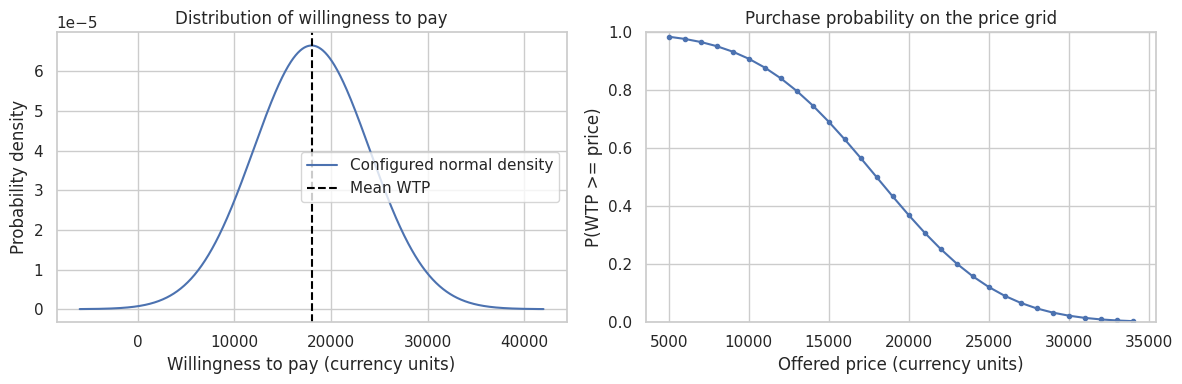

Probability of negative WTP: 0.1350%
Purchase probability at the mean WTP: 50.0%


In [ ]:
x = np.linspace(min(mu - 4 * sigma, price_min), max(mu + 4 * sigma, price_max), 800)
prices = np.arange(price_min, price_max, price_step)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(x, norm.pdf(x, mu, sigma), label='Configured normal density')
axes[0].axvline(mu, color='black', linestyle='--', label='Mean WTP')
axes[0].set(xlabel='Willingness to pay (currency units)', ylabel='Probability density', title='Distribution of willingness to pay')
axes[0].legend()
axes[1].plot(prices, norm.sf(prices, mu, sigma), marker='o', markersize=3)
axes[1].set(xlabel='Offered price (currency units)', ylabel='P(WTP >= price)', ylim=(0, 1), title='Purchase probability on the price grid')
save_chart(fig, '01_willingness_to_pay.png')
print(f'Probability of negative WTP: {norm.cdf(0, mu, sigma):.4%}')
print(f'Purchase probability at the mean WTP: {norm.sf(mu, mu, sigma):.1%}')

## 2. Arrivals: timing weights versus daily arrival probabilities

The left-hand plot shows **discrete probability mass** for potential-customer arrival timing: a lognormal distribution integrated over each daily interval and normalised within the booking horizon. These weights sum to one.

The right-hand plot multiplies each weight by `people` and a demand multiplier. The resulting value is the probability of one potential customer arriving that day. The simulator allows **at most one arrival per day**, so every value must be between zero and one. The sum across days is the expected number of potential arrivals, not the number of accepted bookings.

**Read the horizontal axis carefully:** larger values mean earlier relative to check-in. The simulation proceeds from the largest lead time down to zero.

**Discuss:** Increasing `people` changes the height of the daily arrival probabilities, but does it change the timing weights?

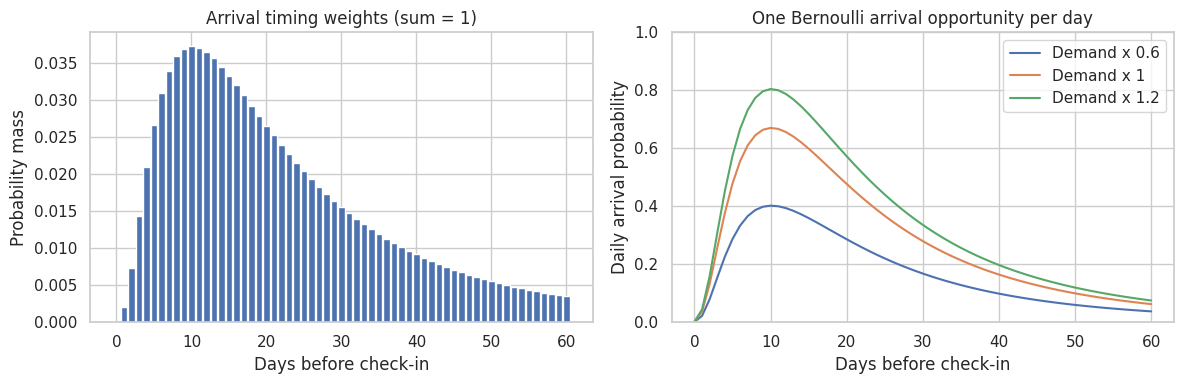

,Demand multiplier,Expected potential arrivals,Maximum daily probability
0,0.6,10.8,0.402193
1,1.0,18.0,0.670321
2,1.2,21.6,0.804385


In [ ]:
weights = visit.loc[days, 'visit'].to_numpy()
arrival_probabilities = {
    multiplier: weights * config['people'] * multiplier
    for multiplier in config['mt_multiplier']
}
assert np.isclose(weights.sum(), 1)
assert all(np.all((p >= 0) & (p <= 1)) for p in arrival_probabilities.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(days, weights, width=0.9)
axes[0].set(xlabel='Days before check-in', ylabel='Probability mass', title='Arrival timing weights (sum = 1)')
for multiplier, probabilities in arrival_probabilities.items():
    axes[1].plot(days, probabilities, label=f'Demand x {multiplier:g}')
axes[1].set(xlabel='Days before check-in', ylabel='Daily arrival probability', ylim=(0, 1), title='One Bernoulli arrival opportunity per day')
axes[1].legend()
save_chart(fig, '02_arrival_probabilities.png')
display(pd.DataFrame([
    {'Demand multiplier': m, 'Expected potential arrivals': p.sum(), 'Maximum daily probability': p.max()}
    for m, p in arrival_probabilities.items()
]))

## Predict before calculating

1. For a fixed offered price, what happens to purchase probability if mean WTP rises?
2. If potential arrivals increase, would you charge more or less when only two rooms remain?
3. How might the answer change when ten rooms remain?

Continue to the pricing section below to test these predictions. The two figures are saved in `fig/distributions/`. To try different input distributions, edit the settings at the top of this notebook and run all again.

## 4. Calculate optimal prices and expected revenue

In [ ]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm
from IPython.display import display
import yaml

with open('config.yaml', encoding='utf-8') as file:
    config = yaml.safe_load(file)
assert config.get('workflow') == 'pricing-workshop-v1', 'Generate a fresh workspace with Notebook 01 first.'

def load_model(name):
    with open(f'model/{name}.pickle', 'rb') as file:
        return pickle.load(file)

price_min, price_max, price_interval = load_model('opt_table_params')
mu, sigma = load_model('wtp_parameters')
visit_curve = load_model('visit_curve')
price_grid = np.arange(price_min, price_max, price_interval)
figure_dir = Path('fig/pricing')
figure_dir.mkdir(parents=True, exist_ok=True)
Path('result').mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')

## Two possible outcomes: sale or no sale

Let $t$ be days before check-in and $c$ the number of rooms still available. A potential customer arrives with probability $a_t$. At price $p$, the purchase probability is $d(p) = \Pr(\mathrm{WTP} \geq p)$.

The probability of a sale is $s(t,p) = a_t d(p)$. Let $V(t,c)$ be optimal expected future revenue. The expected revenue from choosing $p$ is:

$$
s(t,p)\left[p + V(t-1,c-1)\right] + \left[1-s(t,p)\right]V(t-1,c).
$$

We evaluate every allowed price and keep the one with the highest expected revenue. With zero rooms, expected future revenue is zero and sales are closed. After the last period, expected future revenue is also zero. At $t=0$, only today's possible sale matters.

The code works backwards from $t=0$ to larger lead times. `norm.sf` computes the normal tail probability directly. Values are not rounded during optimisation. If multiple prices tie, the lowest price in the grid is selected.

In [ ]:
def create_optimized_price_table(arrival_probabilities, prices, mean_wtp, std_wtp, capacity):
    """Dynamic programming for permanent sales, with one arrival opportunity per day."""
    arrival = np.asarray(arrival_probabilities, dtype=float)
    prices = np.asarray(prices, dtype=float)
    if arrival.ndim != 1 or len(arrival) == 0 or not np.all(np.isfinite(arrival)) or np.any((arrival < 0) | (arrival > 1)):
        raise ValueError('Daily arrival probabilities must lie between zero and one.')
    if prices.ndim != 1 or len(prices) == 0 or not np.all(np.isfinite(prices)) or np.any(prices <= 0) or np.any(np.diff(prices) <= 0):
        raise ValueError('The price grid must be positive, finite and strictly increasing.')
    if isinstance(capacity, bool) or not isinstance(capacity, int) or capacity < 0:
        raise ValueError('Capacity must be a non-negative integer.')
    if not np.isfinite(mean_wtp) or not np.isfinite(std_wtp) or std_wtp <= 0:
        raise ValueError('WTP parameters must be finite, with positive standard deviation.')
    purchase_probability = norm.sf(prices, loc=mean_wtp, scale=std_wtp)
    optimal_prices = np.full((len(arrival), capacity + 1), np.inf)
    expected_revenue = np.zeros((len(arrival), capacity + 1))
    previous = np.zeros(capacity + 1)
    for t, arrival_probability in enumerate(arrival):
        sale_probability = arrival_probability * purchase_probability
        for rooms in range(1, capacity + 1):
            candidate_revenue = (
                sale_probability * (prices + previous[rooms - 1])
                + (1 - sale_probability) * previous[rooms]
            )
            best = int(np.argmax(candidate_revenue))
            optimal_prices[t, rooms] = prices[best]
            expected_revenue[t, rooms] = candidate_revenue[best]
        previous = expected_revenue[t].copy()
    return pd.DataFrame(optimal_prices), pd.DataFrame(expected_revenue)

In [ ]:
opt_price, opt_revenue = {}, {}
for multiplier in config['mt_multiplier']:
    arrival = visit_curve['visit'].to_numpy() * config['people'] * multiplier
    opt_price[multiplier], opt_revenue[multiplier] = create_optimized_price_table(
        arrival, price_grid, mu, sigma, config['capacity'])
    print(f'Demand x {multiplier:g}: expected potential arrivals = {arrival.sum():.1f}')

for name, tables in [('opt_price', opt_price), ('opt_revenue', opt_revenue)]:
    with open(f'model/{name}.pickle', 'wb') as file:
        pickle.dump(tables, file)

rows = []
for multiplier, table in opt_price.items():
    for t in table.index:
        for rooms in table.columns:
            rows.append({'demand_multiplier': multiplier, 'days_before_checkin': t,
                         'remaining_rooms': rooms, 'price': table.loc[t, rooms],
                         'expected_revenue': opt_revenue[multiplier].loc[t, rooms]})
price_results = pd.DataFrame(rows)
price_results.to_csv('result/price_tables.csv', index=False)
display(price_results.head())

Demand x 0.6: expected potential arrivals = 10.8
Demand x 1: expected potential arrivals = 18.0
Demand x 1.2: expected potential arrivals = 21.6


,demand_multiplier,days_before_checkin,remaining_rooms,price,expected_revenue
0,0.6,0,0,inf,0.000000
1,0.6,0,1,14000.0,10.891512
2,0.6,0,2,14000.0,10.891512
3,0.6,0,3,14000.0,10.891512
4,0.6,0,4,14000.0,10.891512


## Compare price tables on the same colour scale

Rows are days before check-in and columns are remaining rooms. The first row is the beginning of the booking horizon. Zero-room states are excluded from the heatmaps because sales are closed there.

Compare **the same cell** across demand levels. A different colour means a different recommended price, not a different probability.

The tables below the heatmaps show every price, with the same lead-time order. Prices are rounded to whole currency units for display (half up) and use thousands separators. The zero-room column shows **Closed**. Calculations and exported CSV values retain their original precision.

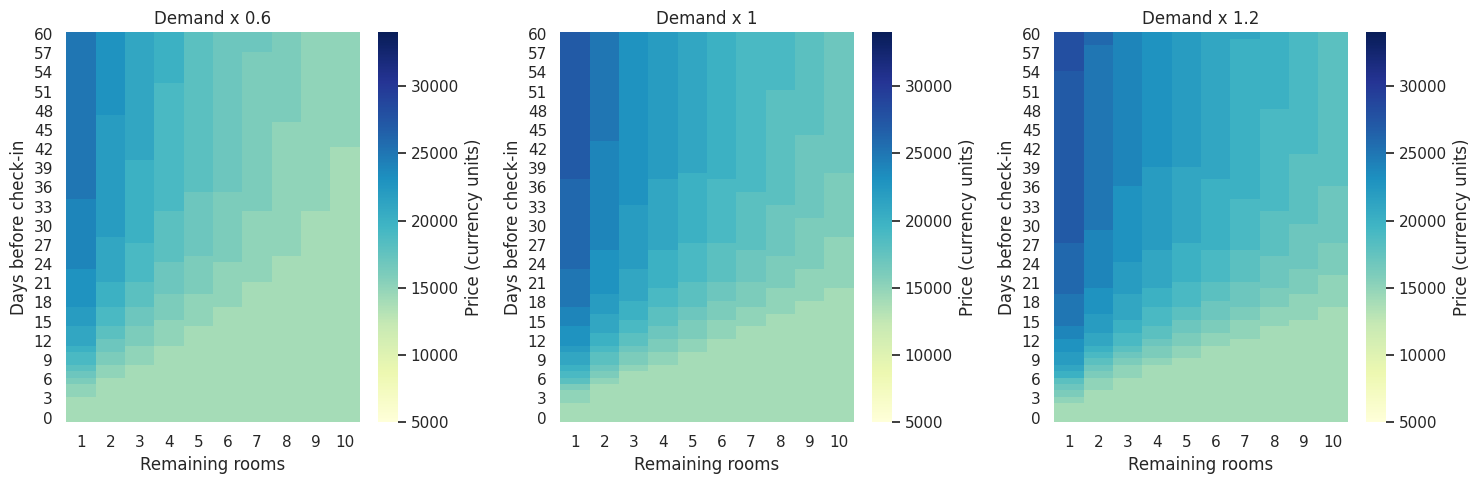

In [ ]:
multipliers = config['mt_multiplier']
fig, axes = plt.subplots(1, len(multipliers), figsize=(5 * len(multipliers), 5), squeeze=False)
for ax, multiplier in zip(axes[0], multipliers):
    table = opt_price[multiplier].iloc[::-1, 1:]
    sns.heatmap(table, ax=ax, cmap='YlGnBu', vmin=price_grid.min(), vmax=price_grid.max(),
                cbar_kws={'label': 'Price (currency units)'})
    ax.set(title=f'Demand x {multiplier:g}', xlabel='Remaining rooms', ylabel='Days before check-in')
fig.tight_layout()
fig.savefig(figure_dir / 'price_tables.png', dpi=140, bbox_inches='tight')
plt.show()
plt.close(fig)

In [ ]:
from decimal import Decimal, ROUND_HALF_UP


def format_display_price(value):
    """Round only the displayed price; keep the underlying table unchanged."""
    if np.isinf(value):
        return 'Closed'
    rounded = Decimal(str(value)).quantize(Decimal('1'), rounding=ROUND_HALF_UP)
    return f'{rounded:,}'


for multiplier in multipliers:
    price_table = opt_price[multiplier].iloc[::-1].rename_axis(
        index='Days before check-in', columns='Remaining rooms')
    display(price_table.style
            .format(format_display_price)
            .set_caption(f'Optimal prices — Demand x {multiplier:g} (currency units)'))

Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","17,000","16,000","15,000","15,000"
59,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","17,000","16,000","15,000","15,000"
58,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","17,000","16,000","15,000","15,000"
57,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
56,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
55,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
54,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
53,Closed,"25,000","23,000","21,000","20,000","18,000","17,000","16,000","16,000","15,000","15,000"
52,Closed,"25,000","23,000","21,000","19,000","18,000","17,000","16,000","16,000","15,000","15,000"


Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
59,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
58,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
57,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
56,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
55,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
54,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
53,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"
52,Closed,"27,000","25,000","23,000","22,000","21,000","20,000","19,000","19,000","18,000","17,000"


Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,Closed,"28,000","26,000","24,000","23,000","22,000","21,000","21,000","20,000","19,000","18,000"
59,Closed,"28,000","26,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
58,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
57,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
56,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
55,Closed,"28,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
54,Closed,"27,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
53,Closed,"27,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"
52,Closed,"27,000","25,000","24,000","23,000","22,000","21,000","20,000","20,000","19,000","18,000"


## Compare optimal expected revenue tables

Each cell shows the maximum expected revenue from the remaining rooms over the remaining selling periods, including today, when prices are chosen optimally. This is a total expected revenue, not a room price, revenue already earned, or a guaranteed outcome.

The rows and columns match the price tables above. Compare the same day and remaining room count across demand levels. Zero remaining rooms give zero future revenue. Values are rounded half up to whole currency units for display only; calculations and exported CSV values retain their original precision.

In [ ]:
for multiplier in multipliers:
    optimized_revenue_table = opt_revenue[multiplier].iloc[::-1].rename_axis(
        index='Days before check-in', columns='Remaining rooms')
    display(optimized_revenue_table.style
            .format(lambda value: f"{Decimal(str(value)).quantize(Decimal('1'), rounding=ROUND_HALF_UP):,}")
            .set_caption(f'Optimal expected revenue — Demand x {multiplier:g} (currency units)'))

Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,0,"21,636","39,986","55,805","69,355","80,771","90,124","97,501","103,054","107,000","109,609"
59,0,"21,620","39,950","55,744","69,266","80,647","89,960","97,296","102,806","106,712","109,286"
58,0,"21,604","39,913","55,681","69,171","80,516","89,788","97,080","102,545","106,410","108,948"
57,0,"21,587","39,874","55,614","69,072","80,379","89,608","96,853","102,271","106,092","108,593"
56,0,"21,569","39,833","55,544","68,967","80,234","89,417","96,615","101,982","105,758","108,220"
55,0,"21,550","39,789","55,470","68,857","80,081","89,217","96,363","101,679","105,407","107,828"
54,0,"21,530","39,744","55,392","68,741","79,920","89,005","96,098","101,359","105,038","107,416"
53,0,"21,509","39,695","55,310","68,619","79,751","88,782","95,818","101,022","104,649","106,983"
52,0,"21,487","39,645","55,223","68,490","79,571","88,546","95,524","100,667","104,239","106,527"


Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,0,"23,861","45,027","64,246","81,815","97,883","112,530","125,789","137,676","148,194","157,332"
59,0,"23,848","44,998","64,198","81,744","97,787","112,405","125,632","137,482","147,959","157,052"
58,0,"23,834","44,967","64,148","81,670","97,686","112,274","125,468","137,278","147,711","156,758"
57,0,"23,819","44,935","64,095","81,593","97,581","112,137","125,294","137,063","147,451","156,447"
56,0,"23,804","44,901","64,039","81,511","97,469","111,991","125,111","136,837","147,176","156,120"
55,0,"23,788","44,865","63,980","81,424","97,351","111,839","124,918","136,598","146,887","155,775"
54,0,"23,771","44,827","63,917","81,333","97,228","111,677","124,715","136,347","146,581","155,412"
53,0,"23,753","44,787","63,852","81,237","97,097","111,507","124,500","136,082","146,259","155,027"
52,0,"23,734","44,745","63,782","81,136","96,959","111,327","124,273","135,802","145,918","154,622"


Remaining rooms,0,1,2,3,4,5,6,7,8,9,10
Days before check-in,,,,,,,,,,,
60,0,"24,576","46,619","66,862","85,606","103,017","119,184","134,153","147,955","160,600","172,068"
59,0,"24,564","46,591","66,817","85,541","102,929","119,072","134,012","147,782","160,391","171,822"
58,0,"24,551","46,563","66,769","85,473","102,838","118,953","133,865","147,600","160,172","171,562"
57,0,"24,537","46,533","66,720","85,401","102,741","118,829","133,709","147,409","159,942","171,289"
56,0,"24,523","46,501","66,667","85,325","102,639","118,698","133,546","147,208","159,699","171,001"
55,0,"24,508","46,468","66,612","85,246","102,532","118,559","133,373","146,995","159,443","170,697"
54,0,"24,492","46,433","66,554","85,162","102,419","118,414","133,191","146,772","159,173","170,376"
53,0,"24,476","46,396","66,493","85,073","102,300","118,260","132,999","146,535","158,887","170,037"
52,0,"24,458","46,356","66,428","84,980","102,174","118,097","132,796","146,286","158,586","169,679"


## Focus on one inventory level

Change `remaining_rooms` below and rerun this cell. This does not change the hotel's total capacity; it selects a column from the calculated tables.

**Discuss:** What happens when only two rooms remain? Does the recommended price stay the same as check-in approaches? The right-hand plot shows differences from baseline demand.

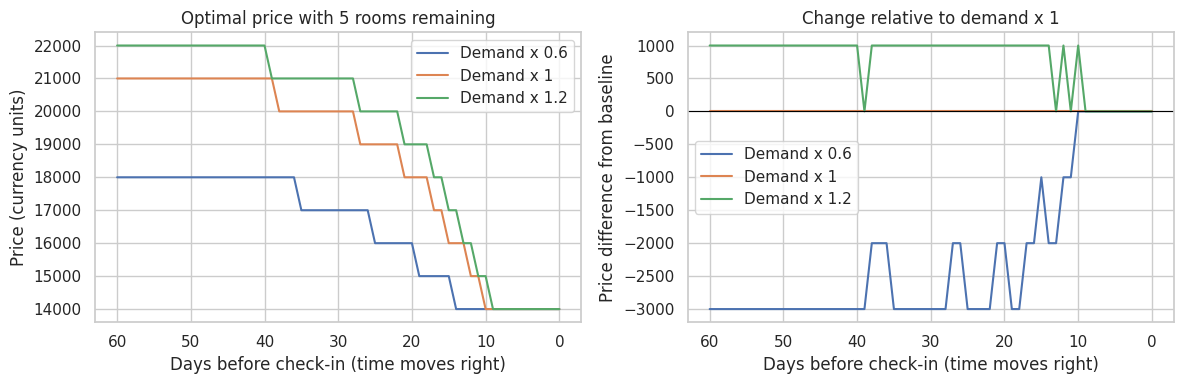

In [ ]:
remaining_rooms = min(5, config['capacity'])  # Try 2, 5 or 10 (up to capacity).
if not 1 <= remaining_rooms <= config['capacity']:
    raise ValueError('Choose a remaining room count between 1 and capacity.')
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for multiplier in multipliers:
    series = opt_price[multiplier][remaining_rooms]
    axes[0].plot(series.index, series, label=f'Demand x {multiplier:g}')
    axes[1].plot(series.index, series - opt_price[1.0][remaining_rooms], label=f'Demand x {multiplier:g}')
for ax in axes:
    ax.invert_xaxis()
    ax.set_xlabel('Days before check-in (time moves right)')
    ax.legend()
axes[0].set(ylabel='Price (currency units)', title=f'Optimal price with {remaining_rooms} rooms remaining')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(ylabel='Price difference from baseline', title='Change relative to demand x 1')
fig.tight_layout()
fig.savefig(figure_dir / 'price_comparison.png', dpi=140, bbox_inches='tight')
plt.show()
plt.close(fig)

## Check and explain

Expected revenue is non-negative. Adding inventory or more selling periods cannot reduce the optimal expected revenue in this model: extra opportunities need not be used. These checks validate values; they do not force a desired price trend.

Price changes can be stepwise because the available prices are on a discrete grid. A change in demand does not have to change every cell.

In [ ]:
for multiplier in multipliers:
    prices = opt_price[multiplier].to_numpy()
    revenue = opt_revenue[multiplier].to_numpy()
    assert np.isinf(prices[:, 0]).all()
    assert np.isin(prices[:, 1:], price_grid).all()
    assert np.isfinite(revenue).all() and (revenue >= 0).all()
    assert np.allclose(revenue[:, 0], 0)
    assert (np.diff(revenue, axis=0) >= -1e-8).all()
    assert (np.diff(revenue, axis=1) >= -1e-8).all()
print('All price-table checks passed.')

All price-table checks passed.


## Explain your result to a partner

- What assumption did you change, or which inventory column did you compare?
- What did you predict before calculating?
- Where did the price change, and where did it stay the same?
- How does the possibility of a future sale affect the decision to accept a lower price now?

To explore another WTP mean or arrival distribution, edit the settings at the top of this notebook and run all again. This workbook ends at optimal pricing. The outputs are deterministic expected values, not sampled outcomes.

## 5. Compare experiments and save the results

After the baseline run, change `wtp_mean` at the top and run all again. This summary compares demand x 1 at 30 days and 5 rooms, where that state exists. Other rows show "not available" if you changed the horizon or inventory below those values. Keep other settings unchanged for the WTP experiment.

Set `download_results = True` in the last cell and run it to download a ZIP of **all experiments from this runtime**. Keep the CSV and figures for comparison. Your runtime files are temporary and are not automatically saved to Drive.

**日本語:** 基準条件と変更後の条件を同じ日数・残室で比較します。最後のセルの `download_results` を `True` にして実行すると、全実験の結果を ZIP で保存できます。ランタイムが終了すると結果ファイルは失われるため、必要なものは終了前にダウンロードしてください。


In [ ]:
comparison_rows = []
for folder in sorted(results_root.iterdir()):
    csv_path = folder / 'result' / 'price_tables.csv'
    if not csv_path.exists():
        continue
    settings = yaml.safe_load((folder / 'scenario.yaml').read_text())
    values = pd.read_csv(csv_path)
    chosen = values.query('demand_multiplier == 1 and days_before_checkin == 30 and remaining_rooms == 5')
    comparison_rows.append({
        'Experiment': folder.name,
        'WTP mean': settings['wtp']['mean'],
        'Days / rooms / demand': '30 / 5 / 1',
        'Optimal price': chosen.iloc[0]['price'] if len(chosen) else 'not available',
        'Expected revenue': chosen.iloc[0]['expected_revenue'] if len(chosen) else 'not available',
    })
display(pd.DataFrame(comparison_rows))


,Experiment,WTP mean,Days / rooms / demand,Optimal price,Expected revenue
0,wtp-18000-yhv4z8p2,18000,30 / 5 / 1,20000.0,90245.659697


In [ ]:
download_results = False  # Change to True and run this cell to save all results.
if download_results:
    import shutil
    archive = shutil.make_archive(str(results_root.parent / 'hotel-pricing-results'), 'zip', results_root)
    try:
        from google.colab import files
    except ImportError:
        print(f'Results ZIP: {archive}')
    else:
        files.download(archive)
